# #236 Historical European 1X2 Market Proxy

This notebook is the executed data-quality review for the Nowscore/Titan-backed `beidan_xlsm` lane. The provider labels `initial`, `10h`, and `1h` remain **RETROSPECTIVE_RELATIVE_PROXY**: they are neither exact issue-time snapshots nor Beijing SP. The notebook profiles fixture and issue/year coverage, bookmakers, missingness, odds and de-vig probability distributions, normalized BJ-line availability, and matching denominators.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'src').is_dir():
    raise RuntimeError('execute this notebook with the repository root as the working directory')
sys.path.insert(0, str(REPO_ROOT / 'src'))
from eu_odds_timeseries.profiling import HORIZONS, build_profiles

data_root_value = os.environ.get('BEIJING_LOT_DATA_ROOT')
if not data_root_value:
    raise RuntimeError('BEIJING_LOT_DATA_ROOT is required; no machine-specific fallback is permitted')
DATA_ROOT = Path(data_root_value).resolve()
WORKBOOK = DATA_ROOT / 'derived' / 'beidan_xlsm' / 'beidan_xlsm.sqlite'
PACKAGE = DATA_ROOT / 'derived' / 'bj236' / 'eu_odds_proxy_v1'
manifest = json.loads((PACKAGE / 'MANIFEST.json').read_text(encoding='utf-8'))
facts = json.loads((PACKAGE / 'report_facts.json').read_text(encoding='utf-8'))
assert manifest['contract'] == 'BJ-UNIFIED-EU-ODDS-TIMESERIES-001'
assert manifest['market_type'] == 'euro_1x2'
assert manifest['causal_grade'] == 'RETROSPECTIVE_RELATIVE_PROXY'
profiles = build_profiles(WORKBOOK, PACKAGE)
profiles['summary'], facts

({'eligible_unique_issue_slots': 192709,
  'matched_proxy_issue_slots': 192443,
  'matched_issue_count': 701,
  'bookmaker_count': 15,
  'calendar_year_min': 2014,
  'calendar_year_max': 2025,
  'unknown_year_fixture_count': 99},
 {'causal_grade': 'RETROSPECTIVE_RELATIVE_PROXY',
  'exclusion_rows': 1516720,
  'market_type': 'euro_1x2',
  'matched_fixture_count': 192443,
  'probability_rows': 1731423,
  'proxy_rows': 1731423,
  'source_sha256': '7f62079b18b3c028884da92aa8393f5b198246c9d7c32cd0b401562a055c5d6f',
  'strict_forward_rows': 0,
  'trace_rows': 578127,
  'translation_rows': 577141})

## Fixture matching and relative-horizon coverage

The denominator is the source's unique non-null Beijing issue-slot population. `source_matrix_row_rate` means at least one source matrix row exists and may still contain only placeholders; `valid_proxy_match_rate` means at least one valid bookmaker triplet survived de-vig validation.

In [2]:
display(profiles['horizon_coverage'])
assert facts['matched_fixture_count'] == profiles['summary']['matched_proxy_issue_slots']
assert facts['strict_forward_rows'] == 0

,snapshot_kind,matched_fixture_count,probability_rows,available_books_median,available_books_p05,available_books_p95,source_matrix_fixture_count,eligible_fixture_count,source_matrix_row_rate,valid_proxy_match_rate
2,initial,192406,577218,11.0,7.0,15.0,192709,192709,1.0,0.998428
0,10h,192297,576891,13.0,10.0,15.0,192709,192709,1.0,0.997862
1,1h,192438,577314,13.0,11.0,15.0,192709,192709,1.0,0.998594


## Issue and calendar-year support

Year is derived from a valid kickoff timestamp and remains `UNKNOWN` when the legacy schedule field is absent or invalid. The complete issue-level table is committed as `ISSUE_COVERAGE.csv`; the notebook shows its distribution rather than printing thousands of rows.

In [3]:
display(profiles['year_coverage'].sort_values(['year', 'snapshot_kind']))
issue_distribution = (profiles['issue_coverage']
    .groupby(['year', 'snapshot_kind'])['matched_fixture_count']
    .agg(issue_count='size', minimum='min', median='median', p95=lambda x: x.quantile(0.95), maximum='max')
    .reset_index())
display(issue_distribution)

,year,snapshot_kind,issue_count,matched_fixture_count
0,2014,10h,141,17411
1,2014,1h,141,17426
2,2014,initial,141,17425
3,2015,10h,62,18222
4,2015,1h,62,18241
5,2015,initial,62,18241
6,2016,10h,61,18862
7,2016,1h,61,18866
8,2016,initial,61,18865
9,2017,10h,55,17073


,year,snapshot_kind,issue_count,minimum,median,p95,maximum
0,2014,10h,141,10,122.0,170.00,538
1,2014,1h,141,10,122.0,170.00,538
2,2014,initial,141,10,122.0,170.00,538
3,2015,10h,62,1,284.0,541.90,646
4,2015,1h,62,1,284.0,542.85,646
5,2015,initial,62,1,284.0,542.85,646
6,2016,10h,61,1,299.0,557.00,645
7,2016,1h,61,1,299.0,557.00,645
8,2016,initial,61,1,299.0,557.00,645
9,2017,10h,55,1,320.0,527.40,572


## Bookmaker coverage and missingness

Bookmaker rows are profiled from the same unique-slot/unique-quote SQL domain as materialization. Invalid triplets never enter the consensus probability and are ledgered.

In [4]:
display(profiles['missingness'])
display(profiles['bookmaker_coverage'][[
    'snapshot_kind', 'bookmaker_id', 'source_matrix_fixture_count',
    'raw_bookmaker_rows', 'valid_bookmaker_rows', 'invalid_bookmaker_rows'
]])

,snapshot_kind,raw_bookmaker_rows,valid_bookmaker_rows,invalid_bookmaker_rows,v1_missing,v2_missing,v3_missing,invalid_triplet_rate,missing_cell_rate
0,initial,2890635,2165010,725625,367073,374496,374496,0.251026,0.128699
1,10h,2890635,2478332,412303,377731,412250,412250,0.142634,0.138635
2,1h,2890635,2512829,377806,374496,377731,377731,0.130700,0.130301


,snapshot_kind,bookmaker_id,source_matrix_fixture_count,raw_bookmaker_rows,valid_bookmaker_rows,invalid_bookmaker_rows
0,initial,10bet,192709,192709,49949,142760
1,initial,18*,192709,192709,183844,8865
2,initial,Bet365,192709,192709,140773,51936
3,initial,Bwin,192709,192709,188102,4607
4,initial,Interwet,192709,192709,185928,6781
5,initial,Oddset,192709,192709,125619,67090
6,initial,Pinna*,192709,192709,125499,67210
7,initial,威廉,192709,192709,188431,4278
8,initial,易博胜,192709,192709,184646,8063
9,initial,澳门,192709,192709,141405,51304


## Raw odds and de-vig probability distributions

Raw-odds statistics are full-valid-row moments (not sampled quantiles). De-vig probability quantiles are exact over all emitted fixture-horizon-outcome rows.

In [5]:
display(profiles['odds_distribution'])
display(profiles['probability_distribution'])

,snapshot_kind,outcome_code,valid_bookmaker_rows,mean_decimal_odds,std_decimal_odds,min_decimal_odds,max_decimal_odds,distribution_grade
0,initial,3,2165010,2.494535,1.602232,1.001000,151.0,FULL_VALID_ROWS_MOMENTS_NO_QUANTILES
1,initial,1,2165010,3.647892,0.926437,1.010000,51.0,FULL_VALID_ROWS_MOMENTS_NO_QUANTILES
2,initial,0,2165010,3.872237,2.946822,1.010000,782.0,FULL_VALID_ROWS_MOMENTS_NO_QUANTILES
3,10h,3,2478332,2.550412,1.723137,1.000551,151.0,FULL_VALID_ROWS_MOMENTS_NO_QUANTILES
4,10h,1,2478332,3.691796,1.007339,1.250000,51.0,FULL_VALID_ROWS_MOMENTS_NO_QUANTILES
5,10h,0,2478332,3.973424,3.103042,1.001000,782.0,FULL_VALID_ROWS_MOMENTS_NO_QUANTILES
6,1h,3,2512829,2.574605,1.781412,1.001000,281.0,FULL_VALID_ROWS_MOMENTS_NO_QUANTILES
7,1h,1,2512829,3.705227,1.051671,1.150000,41.0,FULL_VALID_ROWS_MOMENTS_NO_QUANTILES
8,1h,0,2512829,4.004146,3.178851,1.001000,782.0,FULL_VALID_ROWS_MOMENTS_NO_QUANTILES


,snapshot_kind,outcome_code,count,mean,std,minimum,p05,p25,median,p75,p95,maximum
0,10h,0,192297,0.305243,0.138504,0.017814,0.106190,0.209811,0.289962,0.378832,0.569466,0.932900
1,10h,1,192297,0.260669,0.041730,0.036354,0.173157,0.245243,0.270719,0.287523,0.309225,0.622090
2,10h,3,192297,0.434089,0.153119,0.018444,0.186706,0.332648,0.424422,0.528894,0.707679,0.936669
3,1h,0,192438,0.305684,0.140564,0.019427,0.104867,0.207526,0.290445,0.381048,0.575405,0.938949
4,1h,1,192438,0.260670,0.043082,0.034074,0.170647,0.243794,0.270830,0.288547,0.311785,0.622730
5,1h,3,192438,0.433645,0.155582,0.018622,0.182386,0.329181,0.422729,0.532540,0.711522,0.936464
6,initial,0,192406,0.305352,0.132298,0.021618,0.111688,0.216597,0.292460,0.373166,0.555079,0.927815
7,initial,1,192406,0.260983,0.038901,0.040902,0.178810,0.247968,0.270811,0.285614,0.304974,0.553665
8,initial,3,192406,0.433665,0.146183,0.020447,0.197579,0.340661,0.423942,0.520495,0.697759,0.933165


## Same-provider Asian handicap and total support

The source also has high-coverage two-sided Asian handicap and over/under rows. They are profiled in their native Hong-Kong-odds-plus-line semantics, but are not relabelled or mapped into the Beijing three-outcome probability interface in this Issue.

In [6]:
display(profiles['auxiliary_market_support'])

,market_type,snapshot_kind,source_bookmaker_rows,source_matrix_fixture_count,valid_native_bookmaker_rows,valid_native_fixture_count,eligible_fixture_count,valid_native_fixture_rate,market_semantics,handoff_decision
0,asian_handicap,initial,3468762,192709,1857404,192338,192709,0.998075,TWO_SIDED_HK_ODDS_PLUS_PROVIDER_LINE,PROFILED_NATIVE_AUXILIARY_NOT_MAPPED_TO_BJ_3WAY
1,asian_handicap,10h,3468762,192709,2367193,190634,192709,0.989232,TWO_SIDED_HK_ODDS_PLUS_PROVIDER_LINE,PROFILED_NATIVE_AUXILIARY_NOT_MAPPED_TO_BJ_3WAY
2,asian_handicap,1h,3468762,192709,2416176,192550,192709,0.999175,TWO_SIDED_HK_ODDS_PLUS_PROVIDER_LINE,PROFILED_NATIVE_AUXILIARY_NOT_MAPPED_TO_BJ_3WAY
3,over_under,initial,3468762,192709,2142181,192286,192709,0.997805,TWO_SIDED_HK_ODDS_PLUS_TOTAL_LINE,PROFILED_NATIVE_AUXILIARY_NOT_MAPPED_TO_BJ_3WAY
4,over_under,10h,3468762,192709,2665036,191689,192709,0.994707,TWO_SIDED_HK_ODDS_PLUS_TOTAL_LINE,PROFILED_NATIVE_AUXILIARY_NOT_MAPPED_TO_BJ_3WAY
5,over_under,1h,3468762,192709,2718043,192564,192709,0.999248,TWO_SIDED_HK_ODDS_PLUS_TOTAL_LINE,PROFILED_NATIVE_AUXILIARY_NOT_MAPPED_TO_BJ_3WAY


## BJ-line normalization and translation readiness

Both raw vendor codes and accepted normalized lines remain traceable. Only an integer normalized zero line admits an identity mapping from straight European 1X2 to the Beijing 3/1/0 space. Non-zero lines still require a goal-difference distribution.

In [7]:
display(profiles['line_availability'])
display(profiles['line_provenance'])
assert not profiles['line_availability']['translation_status'].eq('AVAILABLE_NONZERO_LINE').any()

,snapshot_kind,translation_status,fixture_horizon_count,within_horizon_rate
0,10h,AVAILABLE_ZERO_LINE_IDENTITY,113951,0.592578
1,10h,UNAVAILABLE_INVALID_NATIVE_LINE,3,0.000016
2,10h,UNAVAILABLE_MISSING_OR_CONFLICTING_NATIVE_LINE,709,0.003687
3,10h,UNAVAILABLE_NONZERO_LINE_REQUIRES_GOAL_DIFFERENCE,77634,0.403719
4,1h,AVAILABLE_ZERO_LINE_IDENTITY,114041,0.592612
5,1h,UNAVAILABLE_INVALID_NATIVE_LINE,3,0.000016
6,1h,UNAVAILABLE_MISSING_OR_CONFLICTING_NATIVE_LINE,713,0.003705
7,1h,UNAVAILABLE_NONZERO_LINE_REQUIRES_GOAL_DIFFERENCE,77681,0.403668
8,initial,AVAILABLE_ZERO_LINE_IDENTITY,114028,0.592643
9,initial,UNAVAILABLE_INVALID_NATIVE_LINE,3,0.000016


,snapshot_kind,handicap_norm_source,fixture_horizon_count
0,10h,history_join_missing_raw,1871
1,10h,missing_raw,709
2,10h,vendor_large_code_to_zero,112814
3,10h,vendor_small_line,76903
4,1h,history_join_missing_raw,1871
5,1h,missing_raw,713
6,1h,vendor_large_code_to_zero,112904
7,1h,vendor_small_line,76950
8,initial,history_join_missing_raw,1871
9,initial,missing_raw,711


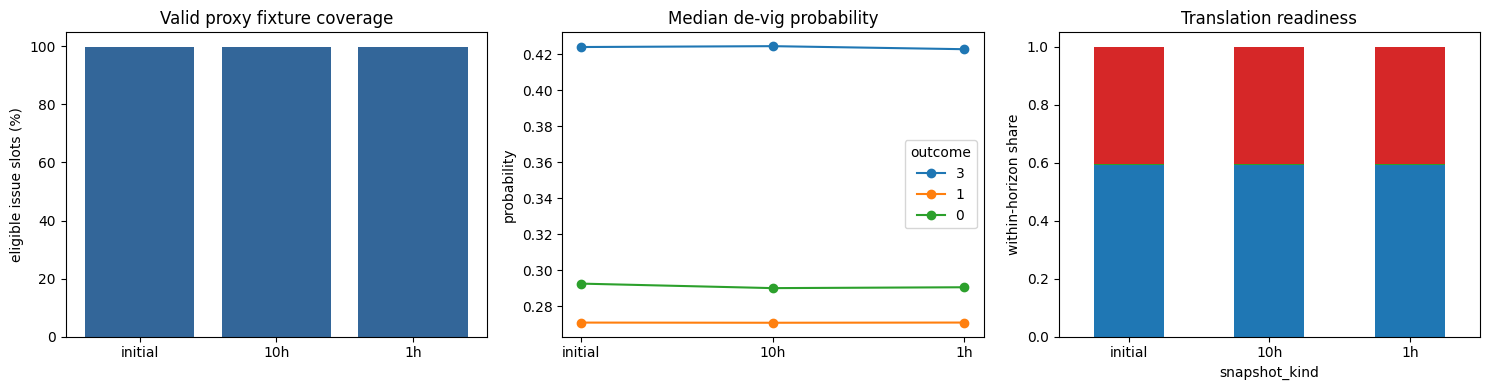

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
coverage = profiles['horizon_coverage']
axes[0].bar(coverage.snapshot_kind, 100 * coverage.valid_proxy_match_rate, color='#336699')
axes[0].set(title='Valid proxy fixture coverage', ylabel='eligible issue slots (%)')
prob = profiles['probability_distribution']
for outcome in ('3', '1', '0'):
    subset = prob.loc[prob.outcome_code.eq(outcome)].set_index('snapshot_kind').reindex(HORIZONS)
    axes[1].plot(HORIZONS, subset['median'], marker='o', label=outcome)
axes[1].set(title='Median de-vig probability', ylabel='probability')
axes[1].legend(title='outcome')
line = profiles['line_availability'].pivot(index='snapshot_kind', columns='translation_status', values='within_horizon_rate').fillna(0).reindex(HORIZONS)
line.plot(kind='bar', stacked=True, ax=axes[2], legend=False)
axes[2].set(title='Translation readiness', ylabel='within-horizon share')
axes[2].tick_params(axis='x', rotation=0)
fig.tight_layout()
plt.show()

## Decision boundary

The historical lane is broad enough to support retrospective relative-horizon modeling, but it does not become strict-forward evidence. Zero-line fixtures can supply `Q_EU_BJLINE` by identity; non-zero-line fixtures remain unavailable until a separate goal-difference model exists. Settlement, winning SP, results, and the 0.65 payout factor were not read into this feature layer.